# GIẢI THÍCH MÔ HÌNH (SHAP + OCCLUSION XAI) & KHAI PHÁ HÀNH ĐỘNG (ACTIONABLE INSIGHTS V4.0)
- Phân tích SHAP toàn cục trên **toàn bộ 2,224 mẫu Test** (`count >= 10`) dùng đúng chỉ số `NEG_IDX = ABSA_STATES.index('Negative')` (= 1).
- Giải thích trực tiếp **PhoBERT ABSA v4.0** bằng **Token-level Occlusion Attribution** (`[UNK]` masking).
- Gom cụm **Actionable Insights** trên 5 nhóm khía cạnh trực tiếp từ `pred_absa_j == 1` (bỏ regex Camera/Màn hình), tách biệt **tổng lượt chê** và **số review tiêu cực unique (`len(df_neg)`)**, trích xuất từ khóa tự động bằng **c-TF-IDF**.

In [1]:
import os, re, sys, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer
from transformers import AutoConfig, AutoTokenizer

ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
PROC_DIR = os.path.join(ROOT, 'data', 'processed')
MODEL_DIR = os.path.join(ROOT, 'models')
FIG_DIR = os.path.join(ROOT, 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

from src.labels import ABSA_COLS, ABSA_STATES, ABSA_STATE_VI, ASPECT_GROUPS
from src.text_cleaner import clean_text
from src.modeling import ABSATemperatureScaler, MAX_LEN_ABSA, PhoBertABSA

NEG_IDX = ABSA_STATES.index('Negative')
assert NEG_IDX == 1
print('NEG_IDX =', NEG_IDX, '| ABSA_STATES =', ABSA_STATES)


NEG_IDX = 1 | ABSA_STATES = ['None', 'Negative', 'Neutral', 'Positive']


In [2]:
#Nạp tập train sạch và kết quả dự đoán Test của PhoBERT ABSA v4.0
df_train = pd.read_csv(os.path.join(PROC_DIR, 'train_clean.csv'), keep_default_na=False)
df_test = pd.read_csv(os.path.join(PROC_DIR, 'test_pred_phobert.csv'), keep_default_na=False)
df_train['sentence_seg'] = df_train['sentence_seg'].fillna('')
df_test['sentence_clean'] = df_test['sentence_clean'].fillna('')
df_test['sentence_seg'] = df_test['sentence_seg'].fillna('')
pred_absa_cols = [f'pred_absa_{j}' for j in range(5)]
df_train.shape, df_test.shape


((7762, 24), (2224, 41))

## 1. PHÂN TÍCH SHAP TOÀN CỤC TRÊN TOÀN BỘ 2,224 MẪU TEST (`NEG_IDX = 1`, `count >= 10`)

In [3]:
#Huấn luyện đầu đọc tuyến tính 4 trạng thái (0=None, 1=Negative, 2=Neutral, 3=Positive) trên TF-IDF và tính SHAP lớp Negative (NEG_IDX=1) theo batch cho toàn bộ 2,224 dòng Test
tfidf = joblib.load(os.path.join(MODEL_DIR, 'tfidf_vectorizer.pkl'))
X_tr = tfidf.transform(df_train['sentence_seg'])
X_te = tfidf.transform(df_test['sentence_seg'])  # Toàn bộ 2,224 dòng Test
bg_tr = shap.sample(X_tr, 100, random_state=42)
vocab = tfidf.get_feature_names_out()
counts = np.asarray((X_te > 0).sum(axis=0)).ravel()
sum_neg_shap = np.zeros(len(vocab), dtype=np.float64)

lr_absa_heads = []
for j in range(5):
    clf_j = LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=42).fit(X_tr, df_train[f'absa_{j}'].values.astype(int))
    lr_absa_heads.append(clf_j)
    exp_j = shap.LinearExplainer(clf_j, bg_tr)
    for start in range(0, X_te.shape[0], 256):
        xb = X_te[start:start + 256]
        sv_b = exp_j.shap_values(xb)
        neg_b = sv_b[:, :, NEG_IDX] if getattr(sv_b, 'ndim', 0) == 3 else sv_b[NEG_IDX]
        pres_b = (xb > 0).toarray()
        sum_neg_shap += np.where(pres_b, neg_b, 0.0).sum(axis=0) / 5.0
print('X_te shape:', X_te.shape, '| Computed exact batched SHAP across all 2,224 Test rows.')


X_te shape: (2224, 15000) | Computed exact batched SHAP across all 2,224 Test rows.


In [4]:
mean_neg = np.zeros(len(vocab))
mask = counts >= 10
mean_neg[mask] = sum_neg_shap[mask] / counts[mask]
top_idx = np.argsort(mean_neg)[-15:]
print('Top 15 từ khóa đẩy mạnh nhất về lớp Negative (NEG_IDX=1, count>=10 trên 2,224 mẫu Test):')
for idx in top_idx[::-1]:
    print(f'  {vocab[idx]:20s}: mean_shap={mean_neg[idx]:.4f} | count={int(counts[idx])}')


Top 15 từ khóa đẩy mạnh nhất về lớp Negative (NEG_IDX=1, count>=10 trên 2,224 mẫu Test):
  thất_vọng           : mean_shap=0.2911 | count=124
  tệ                  : mean_shap=0.2521 | count=150
  chán                : mean_shap=0.2299 | count=100
  kém                 : mean_shap=0.2248 | count=124
  xấu                 : mean_shap=0.1953 | count=43
  chậm                : mean_shap=0.1709 | count=83
  thua                : mean_shap=0.1677 | count=57
  yếu                 : mean_shap=0.1617 | count=104
  mờ                  : mean_shap=0.1540 | count=38
  nhanh hết           : mean_shap=0.1492 | count=28
  quá tệ              : mean_shap=0.1431 | count=57
  không hài_lòng      : mean_shap=0.1411 | count=12
  tuột                : mean_shap=0.1391 | count=60
  rất tệ              : mean_shap=0.1374 | count=21
  hối_hận             : mean_shap=0.1336 | count=24


Đã lưu biểu đồ: D:\E-commerce\reports\figures\shap_top_negative_words.png


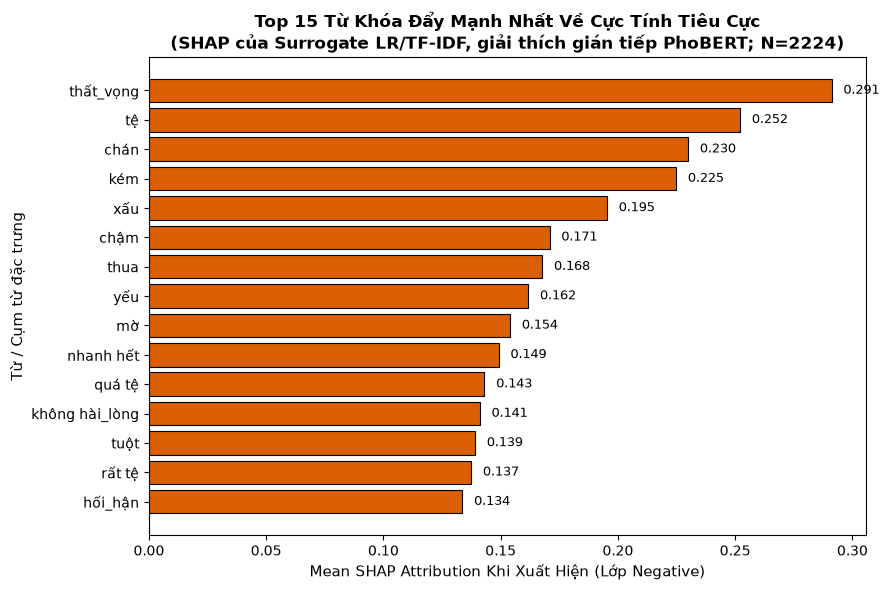

In [5]:
plt.figure(figsize=(9, 6))
words = [vocab[i] for i in top_idx]
scores = mean_neg[top_idx]
bars = plt.barh(words, scores, color='#d95f02', edgecolor='black', linewidth=0.8)
plt.title('Top 15 Từ Khóa Đẩy Mạnh Nhất Về Cực Tính Tiêu Cực\n(SHAP của Surrogate LR/TF-IDF, giải thích gián tiếp PhoBERT; N=2224)', fontsize=12, fontweight='bold')
plt.xlabel('Mean SHAP Attribution Khi Xuất Hiện (Lớp Negative)', fontsize=11)
plt.ylabel('Từ / Cụm từ đặc trưng', fontsize=11)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.005, bar.get_y() + bar.get_height()/2, f'{w:.3f}', va='center', fontsize=9)
plt.tight_layout()
fig_path = os.path.join(FIG_DIR, 'shap_top_negative_words.png')
plt.savefig(fig_path, dpi=150)
print('Đã lưu biểu đồ:', fig_path)
plt.show()


In [6]:
#Giải thích SHAP cục bộ trên 1 mẫu có pred_absa_0 == NEG_IDX (chỉ lấy đóng góp dương sv_neg_one[i] > 0)
neg_cands = df_test[df_test['pred_absa_0'].astype(int) == NEG_IDX].copy()
tempt_row = neg_cands.iloc[0]
tempt_text = tempt_row['sentence_seg']
vec_one = tfidf.transform([tempt_text])
exp_0 = shap.LinearExplainer(lr_absa_heads[0], bg_tr)
sv_one = exp_0.shap_values(vec_one)
sv_neg_one = sv_one[0, :, NEG_IDX] if getattr(sv_one, 'ndim', 0) == 3 else sv_one[NEG_IDX][0]
nonzero_idx = vec_one.nonzero()[1]
word_imp = sorted([(vocab[i], float(sv_neg_one[i])) for i in nonzero_idx if sv_neg_one[i] > 0], key=lambda x: -x[1])
print('Câu mẫu:', tempt_row['sentence_clean'])
print('Top từ đẩy PERF_FEAT về Negative:', word_imp[:5])


Câu mẫu: Mình mới mua vivo91c. Tải ứng dụng ,games nhanh. Có cái không hài lòng là cài hình nền khóa màn hình không được. Hay tại mình chưa biết hết chức năng của nó. Tư vấn viên nhiệt tình
Top từ đẩy PERF_FEAT về Negative: [('tải', 0.16565675996538168), ('không được', 0.14173019646676274), ('không', 0.10410789594028823), ('ứng_dụng', 0.08913631907436112), ('hay', 0.08465931537201997)]


## 2. GIẢI THÍCH TRỰC TIẾP PHOBERT ABSA V4.0 BẰNG TOKEN-LEVEL OCCLUSION XAI

In [7]:
#Dùng Leave-One-Token-Out ([UNK] masking) trực tiếp trên PhoBertABSA để đo độ sụt xác suất P(absa_j = Negative)
SAVE_DIR = os.path.join(MODEL_DIR, 'phobert_absa_v4')
tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
cfg_best = AutoConfig.from_pretrained(SAVE_DIR)
cfg_best.vocab_size = len(tokenizer)
with torch.device('meta'):
    phobert_model = PhoBertABSA(config=cfg_best, dropout=0.2)
phobert_model.load_state_dict(torch.load(os.path.join(SAVE_DIR, 'phobert_absa_best.pt'), map_location='cpu', mmap=True, weights_only=True), assign=True)
phobert_model.encoder.embeddings.position_ids = torch.arange(cfg_best.max_position_embeddings, dtype=torch.long).expand((1, -1))
phobert_model.encoder.embeddings.token_type_ids = torch.zeros(phobert_model.encoder.embeddings.position_ids.size(), dtype=torch.long)
phobert_model.eval()
calib_data = json.load(open(os.path.join(SAVE_DIR, 'calibration.json'), encoding='utf-8'))
ab_scaler = ABSATemperatureScaler.from_dict(calib_data)

def explain_phobert_occlusion(sentence_seg: str, aspect_idx: int, target_state: int = NEG_IDX, top_k: int = 5):
    words = sentence_seg.split()
    if not words:
        return [], 0.0
    variants = [sentence_seg] + [
        ' '.join(words[:i] + [tokenizer.unk_token] + words[i+1:]) for i in range(len(words))
    ]
    enc = tokenizer(variants, padding=True, truncation=True, max_length=MAX_LEN_ABSA, return_tensors='pt')
    with torch.no_grad():
        logits = phobert_model(enc['input_ids'], enc['attention_mask']).numpy()
    probs = ab_scaler.predict_probs(logits)[:, aspect_idx, target_state]
    base_p = float(probs[0])
    drops = [(words[i], round(base_p - float(probs[i + 1]), 4)) for i in range(len(words))]
    drops.sort(key=lambda x: -x[1])
    return drops[:top_k], round(base_p, 4)

#Thử nghiệm Occlusion XAI trên 2 mẫu thực tế (gồm cả câu khen khía cạnh này nhưng chê khía cạnh khác)
mixed_mask = (df_test['pred_absa_2'].astype(int) == NEG_IDX) & ((df_test[pred_absa_cols].values == 3).any(axis=1))
sample_rows = [df_test[mixed_mask].iloc[0], df_test[df_test['pred_absa_0'].astype(int) == NEG_IDX].iloc[0]]
for r, asp_j in zip(sample_rows, [2, 0]):
    top_toks, base_p = explain_phobert_occlusion(r['sentence_seg'], aspect_idx=asp_j, target_state=NEG_IDX)
    print(f'[{ASPECT_GROUPS[asp_j]} | P(Neg)={base_p}] Câu: {r["sentence_clean"]}')
    print('  -> Top token quyết định trên PhoBERT:', top_toks)
del phobert_model
import gc; gc.collect()


[BATTERY | P(Neg)=0.9711] Câu: Nói chung máy đẹp với màn amoled, ổn trong tầm giá,hơi tiếc là thời lượng PIN không cao như quảng cáo
  -> Top token quyết định trên PhoBERT: [('PIN', 0.2708), ('đẹp', 0.0117), ('amoled', 0.0088), ('cao', 0.008), ('giá', 0.0071)]


[PERF_FEAT | P(Neg)=0.5502] Câu: Mình mới mua vivo91c. Tải ứng dụng ,games nhanh. Có cái không hài lòng là cài hình nền khóa màn hình không được. Hay tại mình chưa biết hết chức năng của nó. Tư vấn viên nhiệt tình
  -> Top token quyết định trên PhoBERT: [('được', 0.1215), ('không', 0.0786), ('cái', 0.0615), ('không', 0.0576), ('vivo91c', 0.0523)]


87

## 3. GOM CỤM ACTIONABLE INSIGHTS TRÊN 5 NHÓM KHÍA CẠNH & TRÍCH XUẤT TỪ KHÓA c-TF-IDF

In [8]:
#Định nghĩa df_neg = các review có ít nhất 1 khía cạnh bị dự đoán Negative (pred_absa_j == 1)
pred_absa_mat = df_test[pred_absa_cols].values.astype(int)
has_any_neg = (pred_absa_mat == NEG_IDX).any(axis=1)
df_neg = df_test[has_any_neg].copy()
total_neg_mentions = int((pred_absa_mat == NEG_IDX).sum())
print(f'Số review tiêu cực unique len(df_neg): {len(df_neg)}/{len(df_test)} ({len(df_neg)/len(df_test):.2%})')
print(f'Tổng số lượt chê trên 5 khía cạnh (negative mentions): {total_neg_mentions}')


Số review tiêu cực unique len(df_neg): 1247/2224 (56.07%)
Tổng số lượt chê trên 5 khía cạnh (negative mentions): 2191


In [9]:
#Trích xuất từ khóa đặc trưng tự động bằng c-TF-IDF / log-odds cho từng nhóm khía cạnh tiêu cực (5 cụm đúng 5 đầu ABSA)
VN_STOP = {'và', 'là', 'của', 'có', 'được', 'cho', 'với', 'này', 'thì', 'mà', 'nhưng', 'rất', 'quá', 'lắm', 'cũng', 'không', 'chưa', 'bị', 'mình', 'mua', 'dùng', 'xài', 'máy', 'điện_thoại', 'sản_phẩm', 'con', 'cái', 'ở', 'về', 'khi', 'đã', 'vẫn', 'nên', 'như', 'hơn', 'lại', 'ra', 'vào', 'lên', 'xuống', 'đi', 'đến', 'từ', 'trong', 'ngoài', 'trên', 'dưới', 'sau', 'trước', 'ngày', 'tháng', 'năm', 'lúc', 'samsung', 'oppo', 'xiaomi', 'iphone', 'apple', 'vivo', 'realme', 'huawei', 'nokia', 'thất_vọng', 'tệ', 'chán', 'kém', 'dở', 'tiếc', 'hơi', 'tuy', 'thật', 'thế', 'vậy', 'rồi', 'mới', 'nhiều', 'ít', 'tầm', 'xíu', 'bảo', 'triệu', 'nghìn', 'đồng'}
# Từ cảm xúc chung và tên hãng lặp ở mọi cụm, không chỉ ra được cần sửa gì nên đưa vào stoplist riêng cho keywords

def score_cluster_terms(sub_texts: pd.Series, rest_texts: pd.Series, min_count: int = 5, alpha: float = 0.5) -> dict:
    """Log-odds có prior cho từng cụm; chỉ giữ từ xuất hiện >= min_count trong cụm và không thuộc VN_STOP."""
    cv = CountVectorizer(token_pattern=r'(?u)\b[a-zA-Zà-ỹÀ-Ỹ_]{2,}\b', min_df=3, lowercase=True)
    X_all = cv.fit_transform(pd.concat([sub_texts, rest_texts], ignore_index=True))
    n_sub = len(sub_texts)
    vocab_c = cv.get_feature_names_out()
    sub_raw = np.asarray(X_all[:n_sub].sum(axis=0)).ravel()
    rest_raw = np.asarray(X_all[n_sub:].sum(axis=0)).ravel()
    sub_p = (sub_raw + alpha) / (sub_raw.sum() + alpha * len(sub_raw))
    rest_p = (rest_raw + alpha) / (rest_raw.sum() + alpha * len(rest_raw))
    lo = np.log(sub_p) - np.log(rest_p)
    # Nhan log1p(tan suat) de uu tien tu khoa pho bien va dac trung cua cum, tranh tu hiem
    weighted = np.log1p(sub_raw) * lo
    return {
        t.replace('_', ' '): float(w)
        for t, l_val, w, c in zip(vocab_c, lo, weighted, sub_raw)
        if c >= min_count and l_val > 0 and t.lower() not in VN_STOP and not t.isdigit()
    }

def assign_unique_cluster_keywords(scores_by_cid: dict, top_k: int = 6) -> dict:
    """Mỗi từ chỉ thuộc về 1 cụm duy nhất có điểm log-odds cao nhất."""
    owner = {}
    for cid, sc in scores_by_cid.items():
        for term, val in sc.items():
            if term not in owner or val > owner[term][1]:
                owner[term] = (cid, val)
    return {
        cid: [t for t, _ in sorted(((t, v) for t, (c, v) in owner.items() if c == cid), key=lambda x: -x[1])[:top_k]]
        for cid in scores_by_cid
    }

cluster_defs = [
    (0, 'Hiệu năng & Cấu hình', 'Tối ưu Hiệu năng, Đa nhiệm & Xử lý Giật Lag: Phát hành bản vá tối ưu quản lý RAM/CPU, kiểm soát xung nhịp và rà soát lỗi kết nối wifi/sóng/loa.'),
    (1, 'Màn hình & Camera', 'Nâng cấp Thuật toán Xử lý Ảnh & Kiểm soát Chất lượng Tấm nền Hiển thị: Tinh chỉnh lấy nét/chụp thiếu sáng và siết QC độ nhạy cảm ứng, màn hình.'),
    (2, 'Thời lượng Pin & Sạc', 'Cải thiện Thời lượng Pin, Kiểm soát Nhiệt độ & Củ sạc: Rà soát mạch quản lý nguồn, kiểm định bộ sạc kèm máy và tối ưu ứng dụng chạy ngầm.'),
    (3, 'Giá cả & Hậu mãi', 'Chuẩn hóa Quy trình Bảo hành, CSKH & Chính sách Giá/Hậu mãi: Đào tạo lại thái độ phục vụ, rút ngắn thời gian bảo hành đổi trả và minh bạch ưu đãi.'),
    (4, 'Thiết kế & Tổng quan', 'Nâng cấp Độ bền Vật liệu Ngoại quan, Phụ kiện & Trải nghiệm Tổng thể: Kiểm tra ngoại quan khung viền/mặt lưng và phụ kiện đi kèm trước khi bàn giao.'),
]

insights = []
cluster_scores = {}
union_neg_indices = set()
for asp_id, cluster_name, action_text in cluster_defs:
    mask_j = (df_test[f'pred_absa_{asp_id}'].astype(int) == NEG_IDX)
    sub = df_test[mask_j]
    rest = df_test[~mask_j]
    union_neg_indices.update(sub.index.tolist())
    cluster_scores[asp_id] = score_cluster_terms(sub['sentence_seg'].fillna(''), rest['sentence_seg'].fillna(''))
    auto_kw = ''
    masked_examples = [clean_text(ex, lowercase=False) for ex in sub['sentence'].head(2).tolist()]
    insights.append({
        'cluster_id': len(insights) + 1,
        'aspect_id': asp_id,
        'aspect_cluster': cluster_name,
        'negative_count': int(len(sub)),
        'pct_of_test_reviews': round(len(sub) / len(df_test) * 100, 2),
        'extracted_keywords': auto_kw,
        'matched_keywords': auto_kw,
        'sample_reviews': ' | '.join(masked_examples),
        'recommended_action': action_text,
    })

unique_kw = assign_unique_cluster_keywords(cluster_scores, top_k=6)
for row in insights:
    kw_str = ', '.join(unique_kw[row['aspect_id']])
    row['extracted_keywords'] = kw_str
    row['matched_keywords'] = kw_str
df_insights = pd.DataFrame(insights).sort_values(by='negative_count', ascending=False).reset_index(drop=True)
df_insights['cluster_id'] = range(1, len(df_insights) + 1)
assert len(union_neg_indices) == len(df_neg), f'Unique neg review mismatch: {len(union_neg_indices)} != {len(df_neg)}'
assert int(df_insights['negative_count'].sum()) == total_neg_mentions
print(f'Verified: 5 clusters cover 100% of {len(df_neg)} unique negative reviews ({total_neg_mentions} total negative aspect mentions).')
df_insights[['cluster_id', 'aspect_cluster', 'negative_count', 'pct_of_test_reviews', 'extracted_keywords']]


Verified: 5 clusters cover 100% of 1247 unique negative reviews (2191 total negative aspect mentions).


,cluster_id,aspect_cluster,negative_count,pct_of_test_reviews,extracted_keywords
0,1,Hiệu năng & Cấu hình,817,36.74,"tự nhiên, đơ, treo, khởi động, cột, sai lầm"
1,2,Thiết kế & Tổng quan,425,19.11,"nhựa, cùi, quá tệ, thua, hối hận, khuyên"
2,3,Thời lượng Pin & Sạc,385,17.31,"tuột, sac, tụt, hao, đồng hồ, mau"
3,4,Màn hình & Camera,300,13.49,"xấu, mờ, vàng, ám, nhợt nhạt, tối"
4,5,Giá cả & Hậu mãi,264,11.87,"bảo hành, niềm, phí, lung tung, đắt, càng"


In [10]:
out_csv = os.path.join(PROC_DIR, 'actionable_insights.csv')
df_insights.to_csv(out_csv, index=False, encoding='utf-8-sig')
print('Đã xuất thành công:', out_csv, '| shape:', df_insights.shape)


Đã xuất thành công: D:\E-commerce\data\processed\actionable_insights.csv | shape: (5, 9)
